# Milestone 2 – Feature Engineering and Vectorization
**Project:** Personalized TED Talks Recommendation System Using Machine Learning (SpringBoard Internship)

**Scope (from the project PDF, Module 3):** convert transcripts and tags into numerical representations (TF-IDF), save the fitted vectorizers and matrices, build content-similarity matrices, document parameter choices, and visualise features and similarity scores for interpretability.

**How to run:** put `ted_talks_prepared.csv` (the prepared dataset from Milestone 1) next to this notebook and use *Run All*. Every number shown is computed when the notebook runs; nothing is typed in by hand.

**Dependencies:** `numpy, pandas, scipy, scikit-learn, joblib, matplotlib` (`seaborn` is optional). If one is missing, the first code cell says exactly what to install.

## 1. Setup and dependency check

In [1]:
import importlib.util, json, re, ast, time, warnings
from pathlib import Path

_PIP = {"numpy": "numpy", "pandas": "pandas", "scipy": "scipy", "sklearn": "scikit-learn",
        "joblib": "joblib", "matplotlib": "matplotlib"}
_missing = [pip for mod, pip in _PIP.items() if importlib.util.find_spec(mod) is None]
if _missing:
    raise ImportError("Missing packages: " + ", ".join(_missing) +
                      ".\nInstall them, then restart the kernel:   %pip install " + " ".join(_missing))

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS

try:
    import seaborn as sns            # optional, only used for the heatmap
except ImportError:
    sns = None

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn",
      importlib.import_module("sklearn").__version__, "| seaborn", "yes" if sns else "not installed (optional)")

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | seaborn yes


## 2. Configuration
All choices live in this one cell so they can be changed without touching the rest of the code.

| Setting | Value | Why |
|---|---|---|
| Transcript `ngram_range` | (1, 2) | single words plus short phrases such as *climate change* |
| Transcript `min_df` | 3 | ignore terms that appear in fewer than 3 talks (typos, one-off names) – they cannot link talks |
| Transcript `max_df` | 0.85 | drop terms present in more than 85 % of talks – they do not discriminate |
| Transcript `max_features` | 50 000 | bounds memory; keeps the most frequent terms |
| Transcript `sublinear_tf` | True | uses 1 + log(tf) so a word repeated many times does not dominate a long talk |
| Tag vectorizer | one token per tag, `binary=True` | a tag is either present or not; `min_df=1` because a rare tag is a strong link between two talks |
| Weights | 0.5 transcript / 0.5 tags | a neutral starting assumption, **not** a tuned optimum (see section 11 for an evidence check) |

These are reasoned starting values, not results of tuning.

In [2]:
# ---------------- input ----------------
DATA_CANDIDATES = ["ted_talks_prepared.csv", "ted_talks_final_cleaned.csv"]   # first one found is used
SEARCH_DIRS     = [".", "data", "dataset", "..", "../data"]

# ---------------- columns (checked against the Milestone 1 notebook output) ----------------
COL_ID, COL_TRANSCRIPT, COL_TAGS, COL_TITLE = "talk_id", "transcript", "topics", "title"
COL_SPEAKER, COL_VIEWS, COL_URL = "speaker_1", "views", "url"
COL_RELATED_CANDIDATES = ["related_talk_ids", "related_talks"]   # optional, only used for the proxy check

# ---------------- vectorizer parameters ----------------
TRANSCRIPT_TFIDF = dict(max_features=50_000, ngram_range=(1, 2), min_df=3, max_df=0.85,
                        sublinear_tf=True, strip_accents="unicode", lowercase=True, dtype=np.float32)
TAG_TFIDF        = dict(min_df=1, max_df=1.0, binary=True, lowercase=False,
                        token_pattern=r"[^\s]+", dtype=np.float32)

# Milestone 1 removed apostrophes ("don't" -> "dont"), which sklearn's stop-word list does not cover.
CONTRACTION_STOPWORDS = {"dont", "doesnt", "didnt", "isnt", "arent", "wasnt", "werent", "cant", "couldnt",
                         "wouldnt", "shouldnt", "wont", "im", "ive", "youre", "youve", "youll", "hes", "shes",
                         "thats", "theres", "weve", "theyre", "theyve", "lets", "whats", "applause", "laughter"}
STOP_WORDS = sorted(set(ENGLISH_STOP_WORDS) | CONTRACTION_STOPWORDS)

# ---------------- combination of the two similarities ----------------
W_TRANSCRIPT, W_TAGS = 0.5, 0.5

# ---------------- outputs ----------------
OUTPUT_DIR = Path("milestone2_outputs")
FIG_DIR = OUTPUT_DIR / "figures"
TOP_K = 5
SAVE_SIMILARITY_MATRICES = True     # three float32 N x N .npy files (~64 MB each for 4,005 talks); set False to skip
QUERY_TALK_IDS = [66, 1, 92, 7, 53]  # IDs seen in the Milestone 1 output; replaced by most-viewed talks if absent
TEXT_QUERIES = ["how sleep affects memory and the brain",
                "climate change and renewable energy",
                "why schools should teach creativity"]
HEATMAP_TALKS = 25

for d in (OUTPUT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
w_sum = W_TRANSCRIPT + W_TAGS
assert W_TRANSCRIPT >= 0 and W_TAGS >= 0 and w_sum > 0, "weights must be non-negative and not both zero"
W_T, W_G = W_TRANSCRIPT / w_sum, W_TAGS / w_sum
print(f"Normalised weights -> transcript {W_T:.2f}, tags {W_G:.2f} | stop words: {len(STOP_WORDS)}")

Normalised weights -> transcript 0.50, tags 0.50 | stop words: 344


## 3. Load the prepared dataset
The notebook looks for `ted_talks_prepared.csv` (then `ted_talks_final_cleaned.csv`, the file Milestone 1 saves) in the folders listed above. In Google Colab it offers an upload box; elsewhere it stops with a clear message instead of guessing.

In [3]:
def find_dataset():
    for d in SEARCH_DIRS:
        for name in DATA_CANDIDATES:
            p = Path(d) / name
            if p.is_file():
                return p
    if importlib.util.find_spec("google.colab") is not None:        # Colab only; harmless elsewhere
        from google.colab import files
        print("Dataset not found. Please upload", DATA_CANDIDATES[0])
        up = files.upload()
        if up:
            return Path(next(iter(up)))
    csvs = sorted(str(p) for p in Path(".").glob("*.csv"))
    raise FileNotFoundError(
        f"Could not find any of {DATA_CANDIDATES} in {SEARCH_DIRS} (working folder: {Path.cwd()}).\n"
        f"CSV files in the working folder: {csvs or 'none'}.\n"
        "Place the prepared dataset next to this notebook or edit DATA_CANDIDATES / SEARCH_DIRS in the configuration cell.")

DATA_PATH = find_dataset()
raw = pd.read_csv(DATA_PATH)
print("Dataset file:", DATA_PATH, "| shape:", raw.shape)
print("Columns:", raw.columns.tolist())

missing_cols = [c for c in (COL_ID, COL_TRANSCRIPT, COL_TAGS, COL_TITLE) if c not in raw.columns]
if missing_cols:
    raise KeyError(f"Required column(s) {missing_cols} not found. Update the COL_* names in the configuration cell. "
                   f"Columns present: {raw.columns.tolist()}")
COL_RELATED = next((c for c in COL_RELATED_CANDIDATES if c in raw.columns), None)
print("Related-talks column for the optional proxy check:", COL_RELATED)

Dataset file: ted_talks_prepared.csv | shape: (4005, 42)
Columns: ['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations', 'about_speakers', 'views', 'recorded_date', 'published_date', 'event', 'native_lang', 'available_lang', 'comments', 'duration', 'topics', 'related_talks', 'url', 'description', 'transcript', 'recorded_date_imputed', 'num_speakers', 'num_languages', 'num_topics', 'related_talk_ids', 'comments_missing', 'views_zero_flag', 'duration_min', 'recorded_year', 'published_year', 'published_month', 'talk_age_days', 'log_views', 'views_per_day', 'transcript_word_count', 'words_per_minute', 'event_type', 'views_outlier', 'combined_text', 'combined_text_words', 'title_words', 'description_words', 'transcript_quality']
Related-talks column for the optional proxy check: related_talk_ids


## 4. Data-quality handling
* IDs must be numeric; duplicate IDs keep the first record (so a talk can never be recommended to itself under two rows).
* Missing values **and placeholders** (`unknown`, `nan`, `[]`, …) are treated as *empty*. This matters: Milestone 1 filled missing text with the word "Unknown", which would otherwise be vectorized as a real word.
* A talk with an empty transcript or empty tag list is **kept** – it is simply represented by the modality it does have.

In [4]:
PLACEHOLDERS = {"", "unknown", "nan", "none", "null", "[]", "{}"}

def blank_to_empty(value):
    if value is None or (not isinstance(value, (list, dict)) and pd.isna(value)):
        return ""
    s = re.sub(r"\s+", " ", str(value)).strip()
    return "" if s.lower() in PLACEHOLDERS else s

df = raw.copy()
n_raw = len(df)
df[COL_ID] = pd.to_numeric(df[COL_ID], errors="coerce")
n_bad_id = int(df[COL_ID].isna().sum())
df = df.dropna(subset=[COL_ID]).copy()
df[COL_ID] = df[COL_ID].astype("int64")
n_dup = int(df[COL_ID].duplicated().sum())
df = df.drop_duplicates(subset=COL_ID, keep="first").reset_index(drop=True)

df[COL_TRANSCRIPT] = df[COL_TRANSCRIPT].map(blank_to_empty)
df[COL_TITLE] = df[COL_TITLE].map(blank_to_empty)
for c in (COL_SPEAKER, COL_URL):
    if c in df.columns:
        df[c] = df[c].map(blank_to_empty)
if COL_VIEWS in df.columns:
    df[COL_VIEWS] = pd.to_numeric(df[COL_VIEWS], errors="coerce")

N = len(df)
IDS = df[COL_ID].to_numpy()
ID_TO_IDX = {int(t): i for i, t in enumerate(IDS)}
print(f"Rows in file: {n_raw} | invalid IDs dropped: {n_bad_id} | duplicate IDs dropped: {n_dup} | talks kept: {N}")
print("Empty / placeholder transcripts:", int((df[COL_TRANSCRIPT] == "").sum()))

Rows in file: 4005 | invalid IDs dropped: 0 | duplicate IDs dropped: 0 | talks kept: 4005
Empty / placeholder transcripts: 5


### 4.1 Tag format detection
The tags column can arrive in different shapes depending on how it was preprocessed (`a | b`, a Python list `['a', 'b']`, or – after Milestone 1's `convert_to_text` – one long space-separated string). The format is **detected from the data**, printed, and each tag becomes one token (multi-word tags use underscores internally).

In [5]:
def detect_tag_format(series, sample=500):
    vals = [str(v).strip() for v in series.dropna().head(5000) if str(v).strip().lower() not in PLACEHOLDERS][:sample]
    if not vals:
        return "empty"
    if np.mean([("|" in v) for v in vals]) >= 0.3:
        return "pipe"
    if np.mean([v.startswith("[") for v in vals]) >= 0.3:
        return "list"
    return "space"

def parse_tags(value, fmt):
    s = blank_to_empty(value)
    if not s:
        return []
    if fmt == "pipe":
        parts = s.split("|")
    elif fmt == "list":
        try:
            parsed = ast.literal_eval(s)
            parts = [str(p) for p in parsed] if isinstance(parsed, (list, tuple, set)) else [s]
        except (ValueError, SyntaxError):
            parts = re.findall(r"'([^']+)'|\"([^\"]+)\"", s)
            parts = [a or b for a, b in parts] or s.split()
    else:                       # 'space': tags were joined with spaces, so individual words are the finest unit available
        parts = s.split()
    seen, out = set(), []
    for p in parts:
        t = re.sub(r"\s+", " ", str(p)).strip().lower()
        if t and t not in PLACEHOLDERS and t not in seen:
            seen.add(t)
            out.append(t.replace(" ", "_"))
    return out

TAG_FORMAT = detect_tag_format(raw[COL_TAGS])
tag_lists = [parse_tags(v, TAG_FORMAT) for v in df[COL_TAGS]]
df["tag_doc"] = [" ".join(t) for t in tag_lists]
print("Detected tag format:", TAG_FORMAT)
if TAG_FORMAT == "space":
    print("NOTE: tags are stored as one space-joined string, so multi-word tags (e.g. 'climate change') are represented "
          "as separate words. Use a '|'-separated or list-style topics column to keep multi-word tags intact.")
print("Example tag documents:")
for i in range(min(3, N)):
    print(f"  {df[COL_TITLE].iat[i][:45]!r:50} -> {df['tag_doc'].iat[i][:90]}")
HAS_T = (df[COL_TRANSCRIPT] != "").to_numpy()
HAS_G = (df["tag_doc"] != "").to_numpy()
print(f"\nTalks with a transcript: {HAS_T.sum()} / {N} | with tags: {HAS_G.sum()} / {N} | tags per talk (mean): "
      f"{np.mean([len(t) for t in tag_lists]):.2f}")

Detected tag format: pipe
Example tag documents:
  'Averting the climate crisis'                      -> alternative_energy cars climate_change culture environment global_issues science sustainab
  "The best stats you've ever seen"                  -> africa asia google demo economics global_issues health statistics global_development visua
  'Simplicity sells'                                 -> computers entertainment interface_design media music performance simplicity software techn

Talks with a transcript: 4000 / 4005 | with tags: 4005 / 4005 | tags per talk (mean): 7.92


## 5. TF-IDF vectorization
Two **separate** vectorizers are fitted – one for transcripts, one for tags – so each modality's contribution stays interpretable. They are fitted only on non-empty documents; empty documents become all-zero rows. (This is an unsupervised, whole-corpus representation of the catalogue; there is no train/test target here, so no label leakage.)

In [6]:
t0 = time.time()
trans_docs = df[COL_TRANSCRIPT].tolist()
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)        # sklearn warns that 1-letter stop words are never produced by the tokenizer
    vec_transcript = TfidfVectorizer(stop_words=STOP_WORDS, **TRANSCRIPT_TFIDF)
    try:
        vec_transcript.fit([d for d, m in zip(trans_docs, HAS_T) if m])
    except ValueError as exc:
        raise ValueError(f"Transcript TF-IDF failed: {exc}. For a small dataset lower min_df / raise max_df.") from exc
X_transcript = vec_transcript.transform(trans_docs).astype(np.float32).tocsr()

vec_tags = TfidfVectorizer(**TAG_TFIDF)
try:
    vec_tags.fit([d for d, m in zip(df["tag_doc"], HAS_G) if m])
except ValueError as exc:
    raise ValueError(f"Tag TF-IDF failed: {exc}") from exc
X_tags = vec_tags.transform(df["tag_doc"]).astype(np.float32).tocsr()

# Weighted concatenation: dot(row_i, row_j) = W_T*cos_transcript + W_G*cos_tags when both modalities exist
X_combined = sparse.hstack([X_transcript * np.sqrt(W_T), X_tags * np.sqrt(W_G)], format="csr", dtype=np.float32)

for name, X in (("transcript", X_transcript), ("tags", X_tags), ("combined", X_combined)):
    assert X.shape[0] == N, f"{name}: row count mismatch"
    assert np.isfinite(X.data).all(), f"{name}: non-finite values"
print(f"Fitted in {time.time() - t0:.1f}s")
print("Transcript matrix:", X_transcript.shape, "| Tag matrix:", X_tags.shape, "| Combined:", X_combined.shape)

Fitted in 20.0s
Transcript matrix: (4005, 50000) | Tag matrix: (4005, 457) | Combined: (4005, 50457)


## 6. Feature-matrix analysis

matrix,transcript TF-IDF,tag TF-IDF,combined (weighted)
rows (talks),4.005000e+03,4005.000,4.005000e+03
columns (terms),5.000000e+04,457.000,5.045700e+04
non-zeros,2.126860e+06,31700.000,2.158560e+06
density %,1.062100e+00,1.732,1.068200e+00
memory MB (sparse),1.700000e+01,0.300,1.730000e+01
all-zero rows,5.000000e+00,0.000,0.000000e+00
terms/row mean,5.311000e+02,7.900,5.390000e+02
terms/row median,5.370000e+02,7.000,5.460000e+02
terms/row max,2.235000e+03,33.000,2.243000e+03


A dense 4005 x 4005 float32 similarity matrix needs about 64 MB - the feature matrices stay sparse; similarity is computed in row chunks to keep peak memory low.


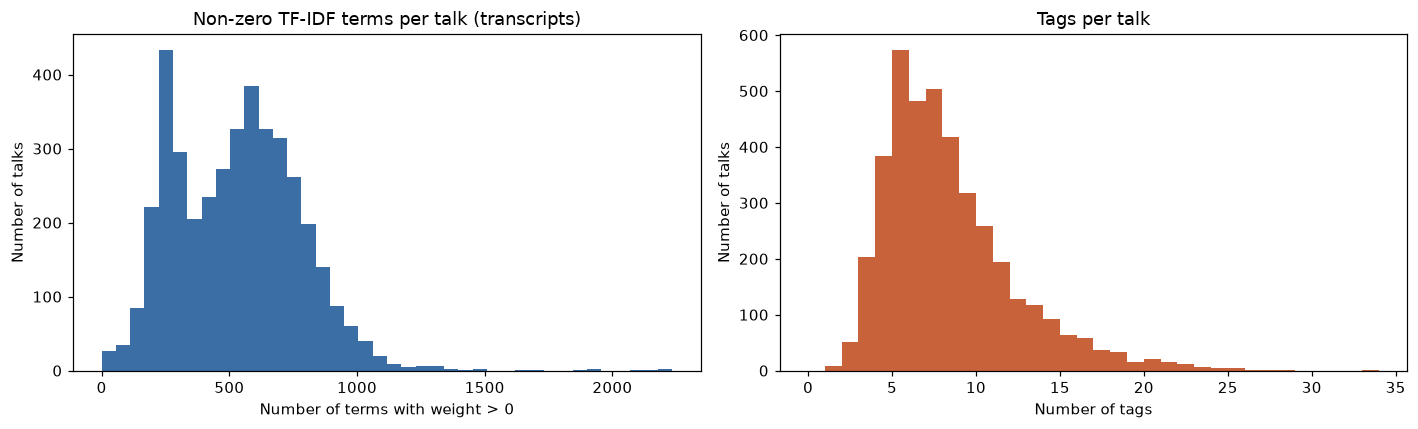

In [7]:
def describe_matrix(name, X):
    nnz_per_row = np.diff(X.indptr)
    return {"matrix": name, "rows (talks)": X.shape[0], "columns (terms)": X.shape[1], "non-zeros": int(X.nnz),
            "density %": round(100 * X.nnz / max(1, X.shape[0] * X.shape[1]), 4),
            "memory MB (sparse)": round((X.data.nbytes + X.indices.nbytes + X.indptr.nbytes) / 1e6, 1),
            "all-zero rows": int((nnz_per_row == 0).sum()),
            "terms/row mean": round(float(nnz_per_row.mean()), 1), "terms/row median": float(np.median(nnz_per_row)),
            "terms/row max": int(nnz_per_row.max())}

matrix_summary = pd.DataFrame([describe_matrix("transcript TF-IDF", X_transcript),
                               describe_matrix("tag TF-IDF", X_tags),
                               describe_matrix("combined (weighted)", X_combined)]).set_index("matrix")
display(matrix_summary.T)
dense_mb = N * N * 4 / 1e6
print(f"A dense {N} x {N} float32 similarity matrix needs about {dense_mb:.0f} MB - the feature matrices stay sparse; "
      "similarity is computed in row chunks to keep peak memory low.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(np.diff(X_transcript.indptr), bins=40, color="#3b6ea5")
axes[0].set(title="Non-zero TF-IDF terms per talk (transcripts)", xlabel="Number of terms with weight > 0", ylabel="Number of talks")
axes[1].hist([len(t) for t in tag_lists], bins=range(0, max(2, max(len(t) for t in tag_lists)) + 2), color="#c8623a")
axes[1].set(title="Tags per talk", xlabel="Number of tags", ylabel="Number of talks")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_feature_matrix_distributions.png", bbox_inches="tight"); plt.show()

## 7. Most important TF-IDF terms
**Aggregation method:** the *mean TF-IDF weight of a term across all talks*. Terms that are frequent inside talks **and** rare across the catalogue score highest. This shows **textual importance in this corpus – it is not causal feature importance** and not a statement about what makes a talk good.

Top 15 transcript terms:


,term,idf,document_frequency,mean_tfidf
0,people,1.176391,3353,0.019808
1,know,1.200226,3274,0.016853
2,going,1.312225,2927,0.016372
3,think,1.273700,3042,0.016138
4,really,1.336422,2857,0.015753
5,world,1.280625,3021,0.015721
6,ve,1.282613,3015,0.015617
7,way,1.203591,3263,0.015326
8,don,1.261615,3079,0.015306
9,years,1.257726,3091,0.015043


Top 15 tags:


,term,idf,document_frequency,mean_tfidf
0,technology,2.407996,979,0.052004
1,science,2.393811,993,0.047703
2,culture,2.771986,680,0.044500
3,ted-ed,2.960494,563,0.038512
4,global issues,2.941179,574,0.037725
5,design,3.043645,518,0.036832
6,tedx,2.929078,581,0.036683
7,animation,3.105233,487,0.033397
8,business,3.199724,443,0.033154
9,society,2.971189,557,0.031309


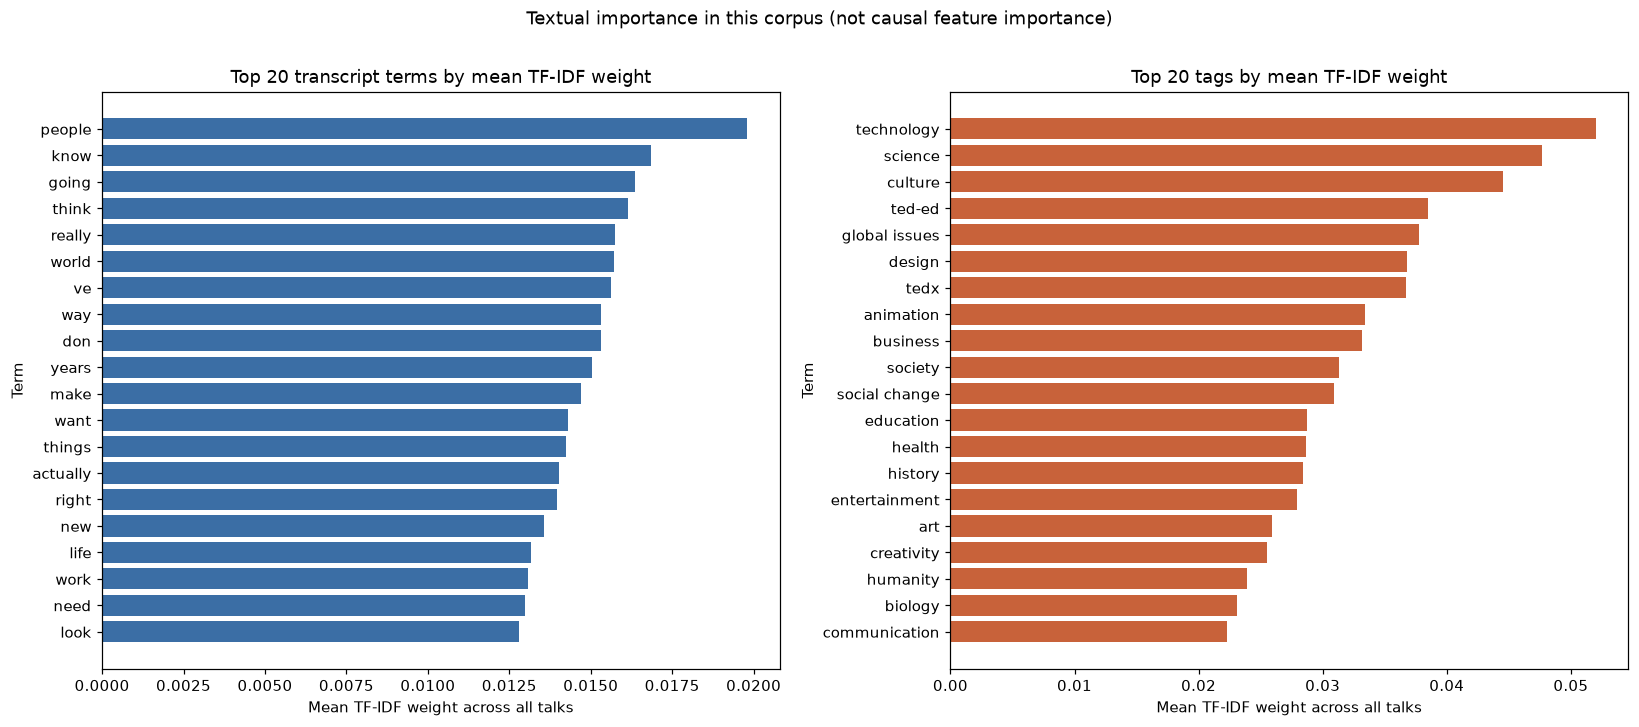

In [8]:
def term_table(vec, X):
    terms = vec.get_feature_names_out()
    return (pd.DataFrame({"term": terms, "idf": vec.idf_, "document_frequency": np.asarray((X > 0).sum(axis=0)).ravel(),
                          "mean_tfidf": np.asarray(X.mean(axis=0)).ravel()})
            .sort_values("mean_tfidf", ascending=False).reset_index(drop=True))

transcript_terms = term_table(vec_transcript, X_transcript)
tag_terms = term_table(vec_tags, X_tags)
tag_terms["term"] = tag_terms["term"].str.replace("_", " ")
print("Top 15 transcript terms:"); display(transcript_terms.head(15))
print("Top 15 tags:");             display(tag_terms.head(15))

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, tbl, title, colour in ((axes[0], transcript_terms, "transcript terms", "#3b6ea5"), (axes[1], tag_terms, "tags", "#c8623a")):
    top = tbl.head(20).iloc[::-1]
    ax.barh(top["term"], top["mean_tfidf"], color=colour)
    ax.set(title=f"Top 20 {title} by mean TF-IDF weight", xlabel="Mean TF-IDF weight across all talks", ylabel="Term")
fig.suptitle("Textual importance in this corpus (not causal feature importance)", y=1.01)
plt.tight_layout(); plt.savefig(FIG_DIR / "02_top_tfidf_terms.png", bbox_inches="tight"); plt.show()

## 8. Cosine similarity matrices
TF-IDF rows are L2-normalised, so **cosine similarity = dot product** of two rows (range 0–1 for non-negative TF-IDF). A score measures *how much text/tag content two talks share* – it is **not an accuracy and not a probability**, and scores are never rescaled here.

**Combined similarity.** `combined = w_t · cos_transcript + w_g · cos_tags` (weights sum to 1, so the result stays in 0–1). A talk with an empty transcript or empty tag list is **still retrievable** through the modality it has, but the missing modality contributes 0, so its combined score is capped at that modality's weight. This is deliberate: re-normalising the weights over the available modality would let a tag-only match score 1.0 and outrank talks that match on both – an artificial inflation. It also means the saved `combined_features.npz` reproduces the combined similarity exactly (its row dot-products equal this weighted sum).

Row/column *i* of every matrix corresponds to row *i* of `talk_index.csv` (saved below), so indices always map back to talk IDs. The product is computed in row chunks to avoid building a huge intermediate sparse matrix.

In [9]:
def cosine_chunked(X, chunk=500):
    n = X.shape[0]
    out = np.zeros((n, n), dtype=np.float32)
    if X.shape[1] == 0:
        return out
    XT = X.T.tocsc()
    for s in range(0, n, chunk):
        out[s:s + chunk] = (X[s:s + chunk] @ XT).toarray()
    return np.clip(out, 0.0, 1.0)            # removes float overshoot such as 1.0000001

def combine(S_t, S_g, w_t, w_g):
    # plain weighted sum: empty documents are all-zero rows, so a missing modality simply contributes 0
    return np.clip(w_t * S_t + w_g * S_g, 0, 1).astype(np.float32)

t0 = time.time()
S_transcript = cosine_chunked(X_transcript)
S_tags = cosine_chunked(X_tags)
S_combined = combine(S_transcript, S_tags, W_T, W_G)
print(f"Similarity matrices computed in {time.time() - t0:.1f}s")

rows = []
for name, S in (("transcript", S_transcript), ("tags", S_tags), ("combined", S_combined)):
    off = S[~np.eye(N, dtype=bool)]
    rows.append({"matrix": name, "shape": S.shape, "finite": bool(np.isfinite(S).all()), "min": float(S.min()),
                 "max": float(S.max()), "mean (off-diagonal)": float(off.mean()),
                 "symmetric": bool(np.allclose(S, S.T, atol=1e-5))})
sim_check = pd.DataFrame(rows).set_index("matrix"); display(sim_check)
assert sim_check["finite"].all() and (sim_check["min"] >= -1e-6).all() and (sim_check["max"] <= 1 + 1e-6).all(), "similarity out of [0,1]"

best = np.array([np.max(np.delete(S_combined[i], i)) for i in range(N)]) if N > 1 else np.array([])
print("Best-match combined score per talk (how similar each talk's closest neighbour is):")
print(pd.Series(best).describe().round(4).to_string())

Similarity matrices computed in 2.5s


,shape,finite,min,max,mean (off-diagonal),symmetric
matrix,,,,,,
transcript,"(4005, 4005)",True,0.0,1.0,0.042364,True
tags,"(4005, 4005)",True,0.0,1.0,0.040407,True
combined,"(4005, 4005)",True,0.0,1.0,0.041385,True


Best-match combined score per talk (how similar each talk's closest neighbour is):
count    4005.0000
mean        0.3821
std         0.0758
min         0.1967
25%         0.3285
50%         0.3726
75%         0.4254
max         0.9135


## 9. Top-5 recommendations (content-based)

In [10]:
def top_k_indices(scores, k, exclude=None):
    s = scores.astype(np.float64).copy()
    if exclude is not None:
        s[exclude] = -np.inf
    k = min(k, len(s) - (1 if exclude is not None else 0))
    if k <= 0:
        return np.array([], dtype=int)
    part = np.argpartition(-s, k - 1)[:k]
    return part[np.lexsort((part, -s[part]))]            # ties broken by lower index -> deterministic

def recommend(talk_id, k=TOP_K, mode="combined"):
    try:
        tid = int(talk_id)
    except (TypeError, ValueError):
        raise ValueError(f"Talk ID must be an integer, got {talk_id!r}")
    if tid not in ID_TO_IDX:
        raise KeyError(f"Unknown talk ID {tid}: not in the {N} processed talks")
    i = ID_TO_IDX[tid]
    S = {"combined": S_combined, "transcript": S_transcript, "tags": S_tags}[mode]
    idx = top_k_indices(S[i], k, exclude=i)
    assert i not in idx                                   # the query talk is never recommended to itself
    out = pd.DataFrame({"rank": np.arange(1, len(idx) + 1), "talk_id": IDS[idx], "title": df[COL_TITLE].to_numpy()[idx]})
    if COL_SPEAKER in df.columns:
        out["speaker"] = df[COL_SPEAKER].to_numpy()[idx]
    out["transcript_sim"] = S_transcript[i, idx].round(4)
    out["tag_sim"] = S_tags[i, idx].round(4)
    out["combined_sim"] = S_combined[i, idx].round(4)
    if COL_URL in df.columns:
        out["url"] = df[COL_URL].to_numpy()[idx]
    return out

# choose query talks: the configured IDs that exist, topped up with the most-viewed talks
query_ids = [t for t in QUERY_TALK_IDS if t in ID_TO_IDX]
if len(query_ids) < 5 and COL_VIEWS in df.columns:
    for t in df.sort_values(COL_VIEWS, ascending=False)[COL_ID]:
        if int(t) not in query_ids:
            query_ids.append(int(t))
        if len(query_ids) >= 5:
            break
query_ids = query_ids[:5]
missing_q = [t for t in QUERY_TALK_IDS if t not in ID_TO_IDX]
if missing_q:
    print("Configured query IDs not in this dataset (replaced):", missing_q)

all_recs = []
for tid in query_ids:
    recs = recommend(tid)
    title = df.loc[df[COL_ID] == tid, COL_TITLE].iat[0]
    print(f"\n=== Query talk {tid}: {title!r} ===")
    display(recs.drop(columns=[c for c in ("url",) if c in recs.columns]))
    assert tid not in set(recs["talk_id"])
    assert recs["combined_sim"].is_monotonic_decreasing
    all_recs.append(recs.assign(query_talk_id=tid, query_title=title))
recommendation_examples = pd.concat(all_recs, ignore_index=True)
print("\nChecks passed: no query talk appears in its own list; scores are sorted in descending order.")


=== Query talk 66: 'Do schools kill creativity?' ===


,rank,talk_id,title,speaker,transcript_sim,tag_sim,combined_sim
0,1,36415,Creative ways to get kids to thrive in school,Olympia Della Flora,0.0916,0.7162,0.4039
1,2,1649,Kids need structure,Colin Powell,0.1036,0.6665,0.3850
2,3,1734,"My story, from gangland daughter to star teacher",Pearl Arredondo,0.0838,0.6319,0.3578
3,4,45972,A new way to get every child ready for kindergarten,Claudia Miner,0.0737,0.5962,0.3349
4,5,35563,How to teach kids to talk about taboo topics,Liz Kleinrock,0.0863,0.5521,0.3192



=== Query talk 1: 'Averting the climate crisis' ===


,rank,talk_id,title,speaker,transcript_sim,tag_sim,combined_sim
0,1,535,What comes after An Inconvenient Truth?,Al Gore,0.1294,0.5171,0.3232
1,2,21646,How China is (and isn't) fighting pollution and climate change,Angel Hsu,0.0911,0.5501,0.3206
2,3,74,The route to a sustainable future,Alex Steffen,0.0862,0.5463,0.3163
3,4,512,A new ecosystem for electric cars,Shai Agassi,0.1008,0.5227,0.3117
4,5,128,Salvation (and profit) in greentech,John Doerr,0.1223,0.4919,0.3071



=== Query talk 92: "The best stats you've ever seen" ===


...


=== Query talk 7: 'Simplicity sells' ===


,rank,talk_id,title,speaker,transcript_sim,tag_sim,combined_sim
0,1,14,Software (as) art,Golan Levin,0.0746,0.5524,0.3135
1,2,2246,New video technology that reveals an object's hidden properties,Abe Davis,0.0787,0.5030,0.2908
2,3,131,Rethink the desktop with BumpTop,Anand Agarawala,0.0722,0.4891,0.2806
3,4,2815,Why our screens make us less happy,Adam Alter,0.0936,0.4656,0.2796
4,5,172,Designing for simplicity,John Maeda,0.1219,0.4165,0.2692



=== Query talk 53: 'Greening the ghetto' ===


,rank,talk_id,title,speaker,transcript_sim,tag_sim,combined_sim
0,1,51,Winning the oil endgame,Amory Lovins,0.1070,0.5714,0.3392
1,2,1041,3 stories of local eco-entrepreneurship,Majora Carter,0.1729,0.4167,0.2948
2,3,209,"Rebuilding a neighborhood with beauty, dignity, hope",Bill Strickland,0.1112,0.4508,0.2810
3,4,929,How big brands can help save biodiversity,Jason Clay,0.0904,0.4448,0.2676
4,5,42702,Why we need darkness,Diane Knutson,0.0719,0.4598,0.2659



Checks passed: no query talk appears in its own list; scores are sorted in descending order.


### 9.1 Free-text queries
A text query is transformed with the **saved, already-fitted** transcript vectorizer (no refitting) and compared with the transcript matrix.

In [11]:
def recommend_text(query, k=TOP_K):
    if query is None or not str(query).strip():
        raise ValueError("Query text is empty")
    q = vec_transcript.transform([str(query)]).astype(np.float32)
    if q.nnz == 0:
        raise ValueError("None of the query words are in the TF-IDF vocabulary (stop words / unseen words are ignored)")
    scores = np.clip((q @ X_transcript.T).toarray().ravel(), 0, 1)
    idx = top_k_indices(scores, k)
    out = pd.DataFrame({"rank": np.arange(1, len(idx) + 1), "talk_id": IDS[idx], "title": df[COL_TITLE].to_numpy()[idx],
                        "similarity": scores[idx].round(4)})
    if COL_SPEAKER in df.columns:
        out.insert(3, "speaker", df[COL_SPEAKER].to_numpy()[idx])
    return out

text_results = []
for q in TEXT_QUERIES:
    try:
        r = recommend_text(q)
        print(f"\n=== Text query: {q!r} ==="); display(r)
        text_results.append(r.assign(query=q))
    except ValueError as exc:
        print(f"\nQuery {q!r} skipped: {exc}")
text_query_examples = pd.concat(text_results, ignore_index=True) if text_results else pd.DataFrame()


=== Text query: 'how sleep affects memory and the brain' ===


,rank,talk_id,title,speaker,similarity
0,1,1813,A mouse. A laser beam. A manipulated memory.,Steve Ramirez,0.1507
1,2,23117,The surprising link between stress and memory,Elizabeth Cox,0.1237
2,3,24257,How memories form and how we lose them,Catharine Young,0.1072
3,4,17698,How sound can hack your memory while you sleep,Greg Gage,0.1068
4,5,2753,The benefits of a good night's sleep,Shai Marcu,0.1056



=== Text query: 'climate change and renewable energy' ===


,rank,talk_id,title,speaker,similarity
0,1,2331,Why climate change is a threat to human rights,Mary Robinson,0.1797
1,2,2562,A small country with big ideas to get rid of fossil fuels,Monica Araya,0.1552
2,3,48919,"How to bring affordable, sustainable electricity to Africa",Rose M. Mutiso,0.1424
3,4,2480,The inside story of the Paris climate agreement,Christiana Figueres,0.1321
4,5,1850,Let's go all-in on selling sustainability,Steve Howard,0.1273



=== Text query: 'why schools should teach creativity' ===


,rank,talk_id,title,speaker,similarity
0,1,407,Do the green thing,Andy Hobsbawm,0.1248
1,2,1219,Shake up your story,Raghava KK,0.0942
2,3,809,Teaching one child at a time,Shukla Bose,0.0885
3,4,24504,The left brain vs. right brain myth,Elizabeth Waters,0.0871
4,5,52396,Why I draw with robots,Sougwen Chung,0.0852


## 10. Similarity visualisations

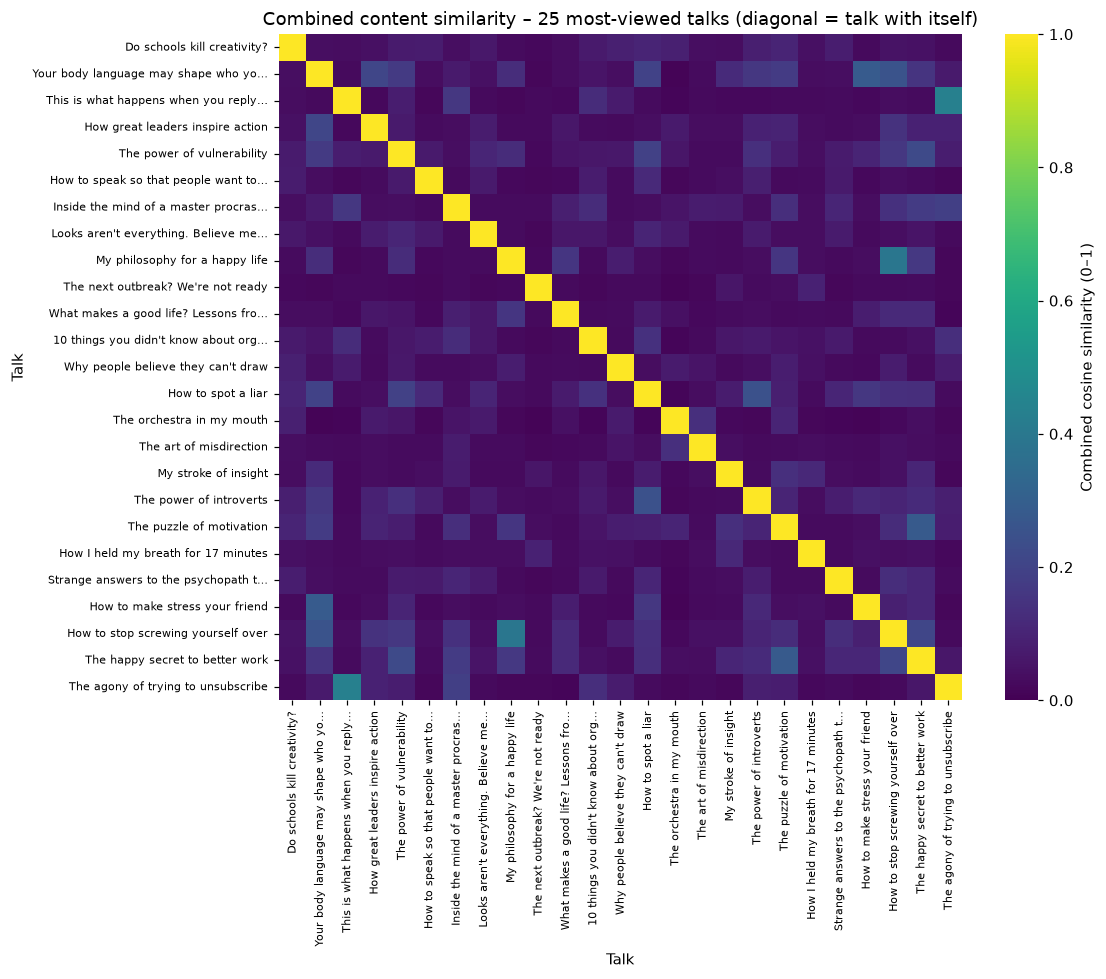

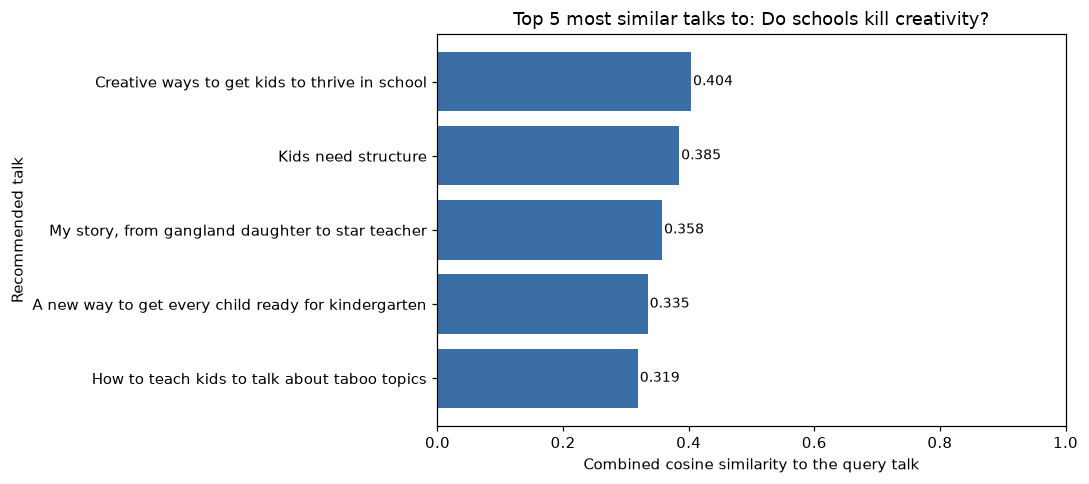

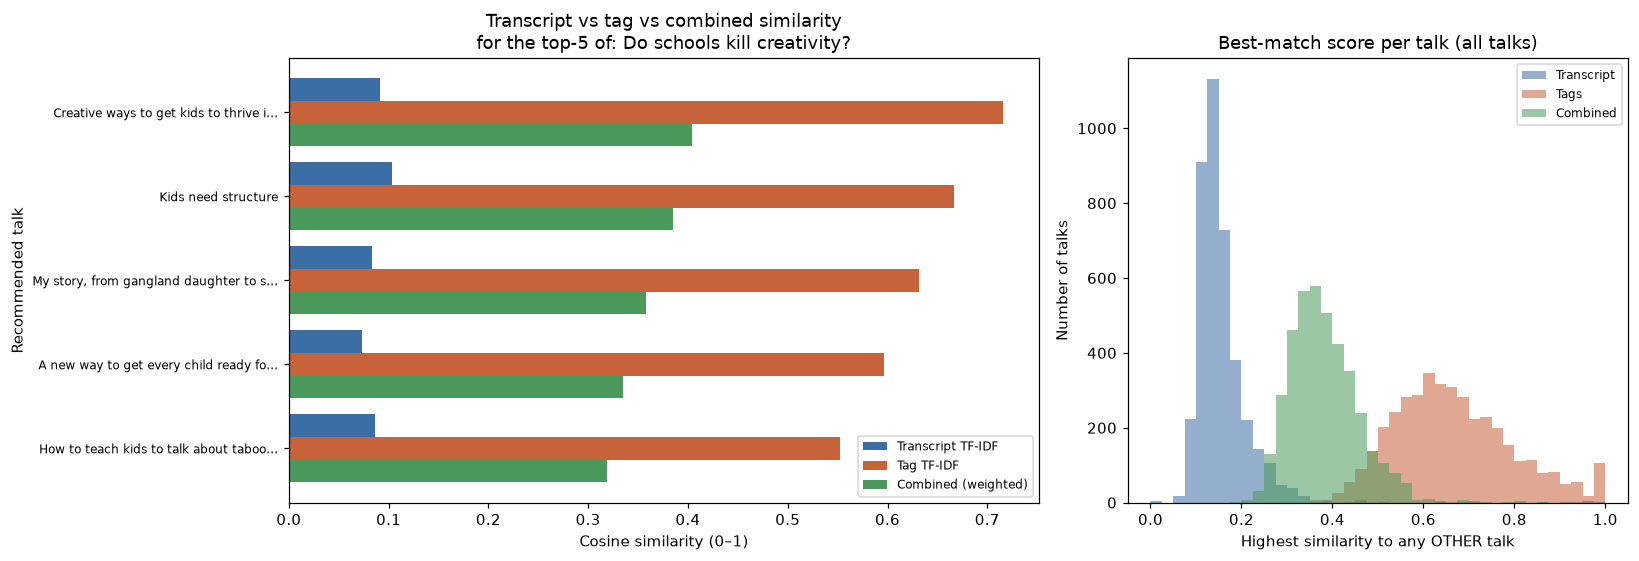

Similarity values are cosine similarities between texts/tags – not model accuracy.


In [12]:
def short(t, n=42):
    t = str(t)
    return t if len(t) <= n else t[:n - 1] + "…"

# --- 10.1 heatmap of the most-viewed talks (a manageable subset, never the whole matrix) ---
order = (df[COL_VIEWS].fillna(0).sort_values(ascending=False).index.to_numpy() if COL_VIEWS in df.columns else np.arange(N))
sub = order[:min(HEATMAP_TALKS, N)]
labels = [short(df[COL_TITLE].iat[i], 36) for i in sub]
fig, ax = plt.subplots(figsize=(10.5, 9))
M = S_combined[np.ix_(sub, sub)]
if sns is not None:
    sns.heatmap(M, ax=ax, cmap="viridis", vmin=0, vmax=1, xticklabels=labels, yticklabels=labels,
                cbar_kws={"label": "Combined cosine similarity (0–1)"})
else:
    im = ax.imshow(M, cmap="viridis", vmin=0, vmax=1); fig.colorbar(im, ax=ax, label="Combined cosine similarity (0–1)")
    ax.set_xticks(range(len(sub))); ax.set_xticklabels(labels); ax.set_yticks(range(len(sub))); ax.set_yticklabels(labels)
plt.setp(ax.get_xticklabels(), rotation=90, fontsize=7); plt.setp(ax.get_yticklabels(), fontsize=7)
ax.set(title=f"Combined content similarity – {len(sub)} most-viewed talks (diagonal = talk with itself)", xlabel="Talk", ylabel="Talk")
plt.tight_layout(); plt.savefig(FIG_DIR / "03_similarity_heatmap.png", bbox_inches="tight"); plt.show()

# --- 10.2 bar chart of the top-5 for the first query talk ---
q0 = query_ids[0]; r0 = recommend(q0); t0_title = df.loc[df[COL_ID] == q0, COL_TITLE].iat[0]
fig, ax = plt.subplots(figsize=(10, 4.5))
d = r0.iloc[::-1]
ax.barh([short(t, 58) for t in d["title"]], d["combined_sim"], color="#3b6ea5")
for y, v in enumerate(d["combined_sim"]):
    ax.text(v + 0.003, y, f"{v:.3f}", va="center", fontsize=9)
ax.set(xlim=(0, max(1.0, float(d["combined_sim"].max()) * 1.12)), xlabel="Combined cosine similarity to the query talk",
       ylabel="Recommended talk", title=f"Top {len(r0)} most similar talks to: {short(t0_title, 60)}")
plt.tight_layout(); plt.savefig(FIG_DIR / "04_top5_bar_chart.png", bbox_inches="tight"); plt.show()

# --- 10.3 transcript vs tag vs combined, and the distribution of best-match scores ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.5, 1]})
y = np.arange(len(r0))[::-1]; h = 0.27
axes[0].barh(y + h, r0["transcript_sim"], h, label="Transcript TF-IDF", color="#3b6ea5")
axes[0].barh(y, r0["tag_sim"], h, label="Tag TF-IDF", color="#c8623a")
axes[0].barh(y - h, r0["combined_sim"], h, label="Combined (weighted)", color="#4c9a5b")
axes[0].set_yticks(y); axes[0].set_yticklabels([short(t, 38) for t in r0["title"]], fontsize=8)
axes[0].set(xlabel="Cosine similarity (0–1)", ylabel="Recommended talk",
            title="Transcript vs tag vs combined similarity\nfor the top-5 of: " + short(t0_title, 45))
axes[0].legend(loc="lower right", fontsize=8)
for name, S, c in (("Transcript", S_transcript, "#3b6ea5"), ("Tags", S_tags, "#c8623a"), ("Combined", S_combined, "#4c9a5b")):
    axes[1].hist(np.array([np.max(np.delete(S[i], i)) for i in range(N)]), bins=40, range=(0, 1), alpha=0.55, label=name, color=c)
axes[1].set(xlabel="Highest similarity to any OTHER talk", ylabel="Number of talks", title="Best-match score per talk (all talks)")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "05_transcript_tag_combined_comparison.png", bbox_inches="tight"); plt.show()
print("Similarity values are cosine similarities between texts/tags – not model accuracy.")

## 11. Optional proxy check against TED's own related-talk links
TED lists "related talks" for each talk. If that column exists, we can measure how often our top-5 contains one of them. **This is a rough proxy, not ground truth and not accuracy:** TED's links are editorial, may themselves rely on tags, and only links to talks present in this dataset can be counted. It is shown only to give *some* evidence for the 0.5 / 0.5 weights; real evaluation of the recommender is the job of Milestone 3.

In [13]:
def parse_related_ids(value):
    if value is None or (not isinstance(value, (list, dict)) and pd.isna(value)):
        return []
    s = str(value)
    try:
        obj = ast.literal_eval(s)
        if isinstance(obj, dict):
            return [int(k) for k in obj.keys()]
        if isinstance(obj, (list, tuple, set)):
            return [int(x) for x in obj]
    except (ValueError, SyntaxError):
        pass
    return [int(x) for x in re.findall(r"\d+", s)] if ":" not in s else [int(x) for x in re.findall(r"(?:^|[{,]\s*)(\d+)\s*:", s)]

proxy_table = pd.DataFrame()
if COL_RELATED is None:
    print("No related-talks column in this dataset - proxy check skipped.")
else:
    related = []
    for i, v in enumerate(df[COL_RELATED].tolist()):
        related.append(sorted({ID_TO_IDX[r] for r in parse_related_ids(v) if r in ID_TO_IDX and ID_TO_IDX[r] != i}))
    evaluable = [i for i, r in enumerate(related) if r]
    print(f"Talks with at least one related talk present in the dataset: {len(evaluable)} / {N}")

    def proxy(S, k=TOP_K):
        hits = rec_sum = 0
        for i in evaluable:
            found = len(set(top_k_indices(S[i], k, exclude=i).tolist()) & set(related[i]))
            hits += found > 0; rec_sum += found / len(related[i])
        return {"hit_rate@5": round(hits / len(evaluable), 4), "mean_recall@5": round(rec_sum / len(evaluable), 4)}

    if evaluable:
        rows = [{"representation": "transcript only", **proxy(S_transcript)}, {"representation": "tags only", **proxy(S_tags)}]
        for w in (0.25, 0.5, 0.75):
            Sw = combine(S_transcript, S_tags, w, 1 - w)
            rows.append({"representation": f"combined, w_transcript={w}", **proxy(Sw)})
        proxy_table = pd.DataFrame(rows).set_index("representation"); display(proxy_table)
        print("Agreement with TED's editorial links only - not accuracy. The configured weights were NOT changed based on this table.")

Talks with at least one related talk present in the dataset: 4004 / 4005


,hit_rate@5,mean_recall@5
representation,,
transcript only,0.7995,0.2522
tags only,0.5235,0.1284
"combined, w_transcript=0.25",0.5554,0.1401
"combined, w_transcript=0.5",0.6141,0.1624
"combined, w_transcript=0.75",0.7170,0.2133


Agreement with TED's editorial links only - not accuracy. The configured weights were NOT changed based on this table.


## 12. Collaborative filtering – feasibility check

In [14]:
user_like = [c for c in raw.columns if re.search(r"user|viewer|customer|session|rating|like|bookmark|watch(ed|_history)?|click", c, re.I)]
print("Columns that could indicate user-level data:", user_like or "none")
print("Aggregate popularity columns present:", [c for c in (COL_VIEWS, "comments") if c in raw.columns])
interaction_check = {"user_level_columns_found": user_like,
                     "collaborative_filtering_implemented": False,
                     "reason": "No user-level interaction data (user IDs with views/ratings/likes). 'views' and 'comments' are "
                               "aggregate counts per talk, not user-item interactions, so no user-item matrix was built."}
print(interaction_check["reason"])

Columns that could indicate user-level data: none
Aggregate popularity columns present: ['views', 'comments']
No user-level interaction data (user IDs with views/ratings/likes). 'views' and 'comments' are aggregate counts per talk, not user-item interactions, so no user-item matrix was built.


**Collaborative filtering is not implemented, and no user–item matrix was created.** The dataset has one row per talk with aggregate counts (`views`, `comments`); it has no user IDs, ratings, likes, bookmarks, or watch histories. Fabricating users or interactions would produce meaningless results. If genuine interaction logs become available, build a sparse CSR user–item matrix (with ID↔index mappings) and add it to this milestone; until then the recommender is content-based.

## 13. Save vectorizers, matrices, similarity matrices and recommendation results

In [15]:
saved = {}
def mark(key, path): saved[key] = str(Path(path).as_posix())

joblib.dump(vec_transcript, OUTPUT_DIR / "tfidf_transcript_vectorizer.joblib"); mark("transcript_vectorizer", OUTPUT_DIR / "tfidf_transcript_vectorizer.joblib")
joblib.dump(vec_tags, OUTPUT_DIR / "tfidf_tags_vectorizer.joblib");             mark("tag_vectorizer", OUTPUT_DIR / "tfidf_tags_vectorizer.joblib")
sparse.save_npz(OUTPUT_DIR / "transcript_tfidf.npz", X_transcript);              mark("transcript_matrix", OUTPUT_DIR / "transcript_tfidf.npz")
sparse.save_npz(OUTPUT_DIR / "tag_tfidf.npz", X_tags);                           mark("tag_matrix", OUTPUT_DIR / "tag_tfidf.npz")
sparse.save_npz(OUTPUT_DIR / "combined_features.npz", X_combined);               mark("combined_matrix", OUTPUT_DIR / "combined_features.npz")

talk_index = pd.DataFrame({"matrix_index": np.arange(N), "talk_id": IDS, "title": df[COL_TITLE],
                           "has_transcript": HAS_T, "has_tags": HAS_G})
talk_index.to_csv(OUTPUT_DIR / "talk_index.csv", index=False);                   mark("talk_index", OUTPUT_DIR / "talk_index.csv")
transcript_terms.head(500).to_csv(OUTPUT_DIR / "top_transcript_terms.csv", index=False); mark("top_transcript_terms", OUTPUT_DIR / "top_transcript_terms.csv")
tag_terms.to_csv(OUTPUT_DIR / "tag_terms.csv", index=False);                     mark("tag_terms", OUTPUT_DIR / "tag_terms.csv")
matrix_summary.to_csv(OUTPUT_DIR / "feature_matrix_summary.csv");                mark("feature_matrix_summary", OUTPUT_DIR / "feature_matrix_summary.csv")

if SAVE_SIMILARITY_MATRICES:
    for key, S in (("transcript", S_transcript), ("tags", S_tags), ("combined", S_combined)):
        np.save(OUTPUT_DIR / f"similarity_{key}.npy", S); mark(f"similarity_{key}", OUTPUT_DIR / f"similarity_{key}.npy")

recommendation_examples.to_csv(OUTPUT_DIR / "recommendations_top5_examples.csv", index=False); mark("recommendation_examples", OUTPUT_DIR / "recommendations_top5_examples.csv")
if len(text_query_examples):
    text_query_examples.to_csv(OUTPUT_DIR / "recommendations_text_queries.csv", index=False); mark("text_query_recommendations", OUTPUT_DIR / "recommendations_text_queries.csv")

# top-5 neighbours for EVERY talk (readable, reusable by Milestone 3)
nb_rows = []
for i in range(N):
    for rank, j in enumerate(top_k_indices(S_combined[i], TOP_K, exclude=i), 1):
        nb_rows.append((int(IDS[i]), df[COL_TITLE].iat[i], rank, int(IDS[j]), df[COL_TITLE].iat[j],
                        round(float(S_combined[i, j]), 4), round(float(S_transcript[i, j]), 4), round(float(S_tags[i, j]), 4)))
pd.DataFrame(nb_rows, columns=["talk_id", "title", "rank", "neighbor_id", "neighbor_title", "combined_sim", "transcript_sim", "tag_sim"]) \
    .to_csv(OUTPUT_DIR / "top5_neighbors_all_talks.csv", index=False);          mark("top5_neighbors_all_talks", OUTPUT_DIR / "top5_neighbors_all_talks.csv")
if len(proxy_table):
    proxy_table.to_csv(OUTPUT_DIR / "proxy_check_related_talks.csv");           mark("proxy_check", OUTPUT_DIR / "proxy_check_related_talks.csv")

metadata = {
    "dataset": {"file": str(DATA_PATH), "rows_in_file": int(n_raw), "invalid_ids_dropped": n_bad_id, "duplicate_ids_dropped": n_dup,
                "talks_used": int(N), "talks_with_transcript": int(HAS_T.sum()), "talks_with_tags": int(HAS_G.sum()),
                "columns_used": [c for c in (COL_ID, COL_TRANSCRIPT, COL_TAGS, COL_TITLE, COL_SPEAKER, COL_VIEWS, COL_URL, COL_RELATED) if c]},
    "tag_format_detected": TAG_FORMAT,
    "parameters": {"transcript_tfidf": {k: (list(v) if isinstance(v, tuple) else (np.dtype(v).name if k == "dtype" else v)) for k, v in TRANSCRIPT_TFIDF.items()},
                   "transcript_stop_words": len(STOP_WORDS),
                   "tag_tfidf": {k: (np.dtype(v).name if k == "dtype" else v) for k, v in TAG_TFIDF.items()},
                   "weights_requested": [W_TRANSCRIPT, W_TAGS], "weights_normalised": [W_T, W_G], "seed": SEED},
    "dimensions": {"transcript_matrix": list(X_transcript.shape), "tag_matrix": list(X_tags.shape),
                   "combined_matrix": list(X_combined.shape), "similarity_matrix": [N, N]},
    "similarity_check": sim_check.reset_index().astype(str).to_dict("records"),
    "interaction_data": interaction_check,
    "versions": {"numpy": np.__version__, "pandas": pd.__version__, "scipy": __import__("scipy").__version__,
                 "scikit-learn": importlib.import_module("sklearn").__version__},
    "files": saved,
}
(OUTPUT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2, default=str), encoding="utf-8"); mark("metadata", OUTPUT_DIR / "metadata.json")

print("Saved files:")
for p in sorted(OUTPUT_DIR.rglob("*")):
    if p.is_file():
        print(f"  {p.as_posix():60} {p.stat().st_size / 1e6:8.2f} MB")

Saved files:
  milestone2_outputs/combined_features.npz                        10.84 MB
  milestone2_outputs/feature_matrix_summary.csv                    0.00 MB
  milestone2_outputs/figures/01_feature_matrix_distributions.png     0.03 MB
  milestone2_outputs/figures/02_top_tfidf_terms.png                0.07 MB
  milestone2_outputs/figures/03_similarity_heatmap.png             0.14 MB
  milestone2_outputs/figures/04_top5_bar_chart.png                 0.04 MB
  milestone2_outputs/figures/05_transcript_tag_combined_comparison.png     0.06 MB
  milestone2_outputs/metadata.json                                 0.00 MB
  milestone2_outputs/proxy_check_related_talks.csv                 0.00 MB
  milestone2_outputs/recommendations_text_queries.csv              0.00 MB
  milestone2_outputs/recommendations_top5_examples.csv             0.00 MB
  milestone2_outputs/similarity_combined.npy                      64.16 MB
  milestone2_outputs/similarity_tags.npy                          64.16 MB
  

## 14. Reload test – are the saved artifacts reusable?
Loads the saved files from disk (as the Milestone 3 recommendation engine will), checks shapes, and confirms that a **reloaded** vectorizer + matrices give the same recommendations as the in-memory objects. The vectorizer is only *applied*, never refitted.

In [16]:
v_t = joblib.load(OUTPUT_DIR / "tfidf_transcript_vectorizer.joblib")
v_g = joblib.load(OUTPUT_DIR / "tfidf_tags_vectorizer.joblib")
Xt2 = sparse.load_npz(OUTPUT_DIR / "transcript_tfidf.npz").tocsr()
Xg2 = sparse.load_npz(OUTPUT_DIR / "tag_tfidf.npz").tocsr()
Xc2 = sparse.load_npz(OUTPUT_DIR / "combined_features.npz").tocsr()
idx2 = pd.read_csv(OUTPUT_DIR / "talk_index.csv")

checks = {
    "transcript matrix shape matches vectorizer vocabulary": Xt2.shape == (N, len(v_t.vocabulary_)),
    "tag matrix shape matches vectorizer vocabulary":        Xg2.shape == (N, len(v_g.vocabulary_)),
    "combined matrix width = transcript + tag width":        Xc2.shape == (N, Xt2.shape[1] + Xg2.shape[1]),
    "talk_index rows = matrix rows, IDs unique":              len(idx2) == N and idx2["talk_id"].is_unique,
    "reloaded matrices equal in-memory matrices":             (abs(Xt2 - X_transcript).max() < 1e-6) and (abs(Xg2 - X_tags).max() < 1e-6),
}
probe = TEXT_QUERIES[0]
q_new, q_old = v_t.transform([probe]), vec_transcript.transform([probe])
checks["reloaded vectorizer transforms text identically"] = (abs(q_new - q_old).max() < 1e-9) if q_old.nnz else True
i0 = ID_TO_IDX[query_ids[0]]
row_re = (Xt2[i0] @ Xt2.T).toarray().ravel()
checks["reloaded matrix reproduces the transcript similarity row"] = bool(np.allclose(np.clip(row_re, 0, 1), S_transcript[i0], atol=1e-5))
row_c = np.clip((Xc2[i0] @ Xc2.T).toarray().ravel(), 0, 1)
checks["combined_features.npz reproduces the combined similarity row"] = bool(np.allclose(row_c, S_combined[i0], atol=1e-4))
if SAVE_SIMILARITY_MATRICES:
    S_re = np.load(OUTPUT_DIR / "similarity_combined.npy", mmap_mode="r")
    checks["saved combined similarity loads, correct shape, finite"] = (S_re.shape == (N, N)) and bool(np.isfinite(S_re).all())
    checks["saved combined similarity gives same top-5 as memory"] = list(top_k_indices(np.asarray(S_re[i0]), TOP_K, exclude=i0)) == list(top_k_indices(S_combined[i0], TOP_K, exclude=i0))
for name, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", name)
assert all(checks.values()), "A reload check failed - see the lines marked FAIL above"
print("\nAll reload checks passed.")

PASS - transcript matrix shape matches vectorizer vocabulary
PASS - tag matrix shape matches vectorizer vocabulary
PASS - combined matrix width = transcript + tag width
PASS - talk_index rows = matrix rows, IDs unique
PASS - reloaded matrices equal in-memory matrices
PASS - reloaded vectorizer transforms text identically
PASS - reloaded matrix reproduces the transcript similarity row
PASS - combined_features.npz reproduces the combined similarity row
PASS - saved combined similarity loads, correct shape, finite
PASS - saved combined similarity gives same top-5 as memory

All reload checks passed.


## 15. Summary of this milestone

**Implemented (all values printed above come from the run):**
* Two separate TF-IDF representations – transcripts (unigrams + bigrams) and tags (one token per tag) – with documented parameters.
* Feature-matrix analysis (shape, sparsity, memory, terms per talk) and a term-importance chart with its aggregation method stated.
* Cosine similarity matrices for transcript, tags and a configurable weighted combination; talks missing a modality stay retrievable but are not score-inflated.
* Top-5 recommendations for several query talks and free-text queries, with transcript / tag / combined scores shown separately.
* Saved vectorizers, sparse matrices, similarity matrices, term tables, recommendation results, figures and `metadata.json`, plus a reload test.

**Not implemented, by design:** collaborative filtering (no genuine user–item data – section 12) and sentence embeddings (optional in the PDF; TF-IDF is the required baseline here). No claim is made that one representation is better than another beyond the proxy table in section 11, which measures agreement with TED's editorial links only.

**How to read the scores.** Cosine similarity is a measure of shared vocabulary / tags. Moderate values (for example 0.2–0.4) are typical when two talks share a topic but not most of their wording; they are not "low accuracy". Judge relevance by reading the recommended titles in section 9.

**Limitations.** TF-IDF matches words, not meaning (synonyms are not linked); long and short transcripts differ in vocabulary richness; if tags arrive as one space-joined string, multi-word tags are split into words; full N × N matrices use O(N²) memory (about 64 MB per matrix for 4,005 talks).

**Next (Milestone 3):** load the saved artifacts to build and evaluate the recommendation engine with Precision@K, Recall@K, NDCG and MAP.